# Machine Learning and Neural Networks

## Tutorial 3: Unsupervised learning

Welcome to the third tutorial for Machine Learning and Neural Netowkrs. In this session, we will explore how to apply some simple unsupervised learning algorithms. The first part of the tutorial explores Clustering, and the second Association Rules.

### Clustering

Throughout this section we will use routines implemented in scikit-learn.

#### Problem 1: K-Means clustering

Scikit-learn includes a number of datasets that you can use to test your models on. For this problem, we will use the [UCI Wine recognition](https://scikit-learn.org/1.5/datasets/toy_dataset.html#wine-recognition-dataset) dataset. Using that dataset, perform K-means clustering on the data and see if the clusters correspond to the production by each of the 3 producers (vinters).

This problem consists of a number of steps:
1. Load the dataset
2. Apply K-means to the data
  - First ask yourself: what is a reasonable number of clusters to try?
3. Visualise the results
  - Plot the pairs of features coloured by clusters
  - And plot the true labels to compare with the clusters
4. Evaluate the model by calculating the interia, and by plotting the confusion matrix between the clusters and the true labels

##### Follow-up questions:

How well does K-means perform in separating the different Vinters?

What are the limitations of using K-means for this dataset?

Dataset shape: (178, 13)
Number of classes: 3
Class names: ['class_0' 'class_1' 'class_2']
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.8

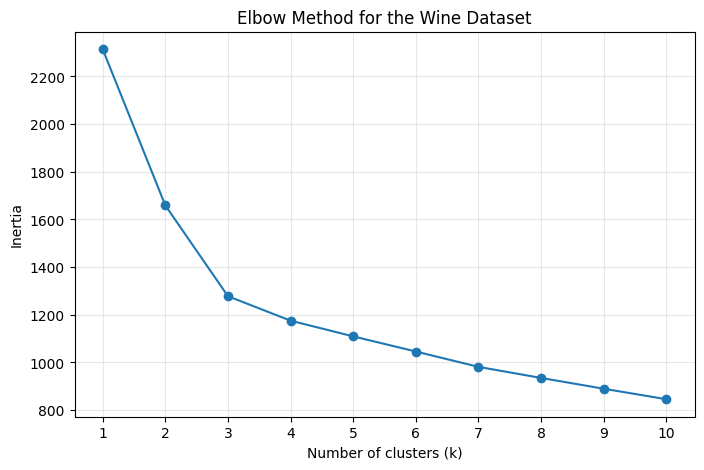

Inertia: 1277.928488844643
Cluster sizes: [65 51 62]


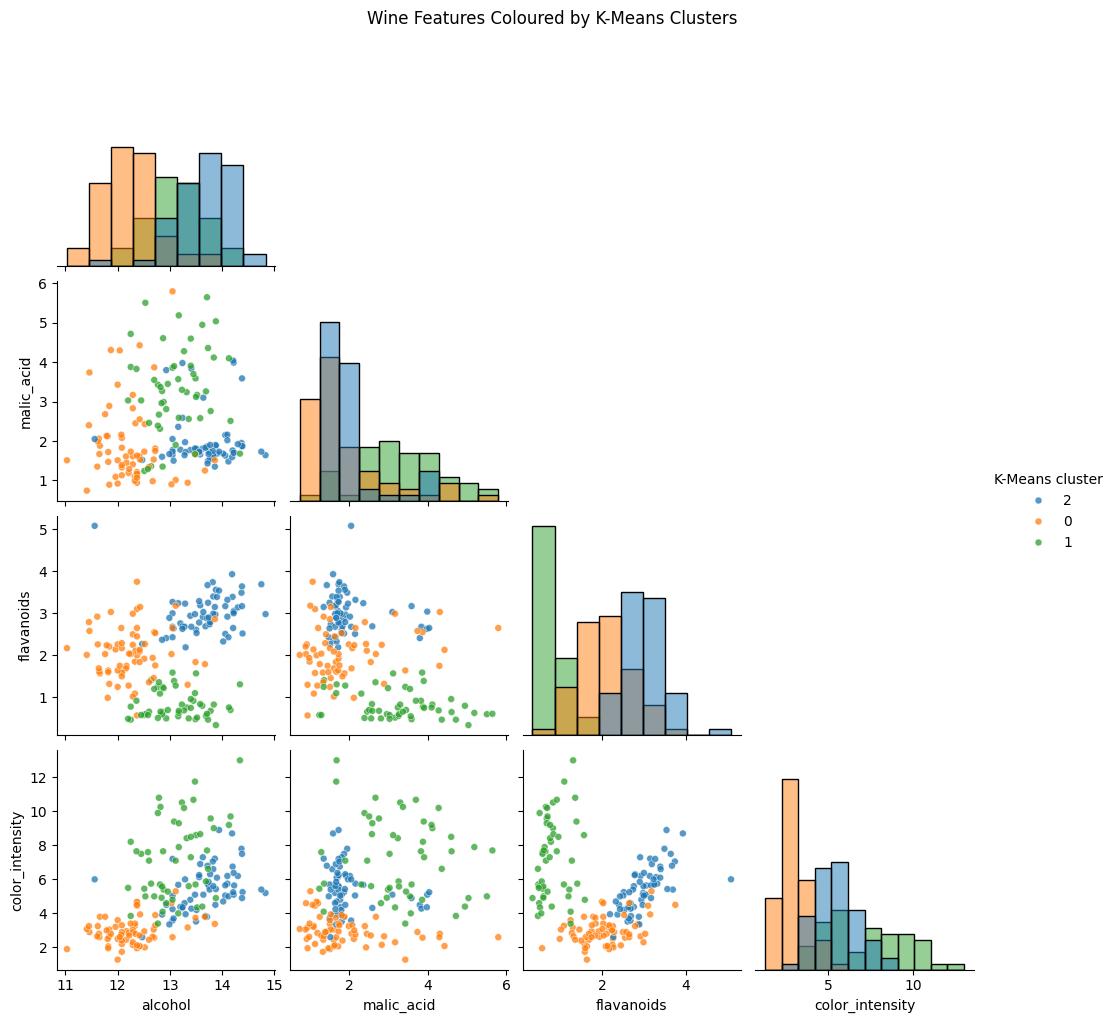

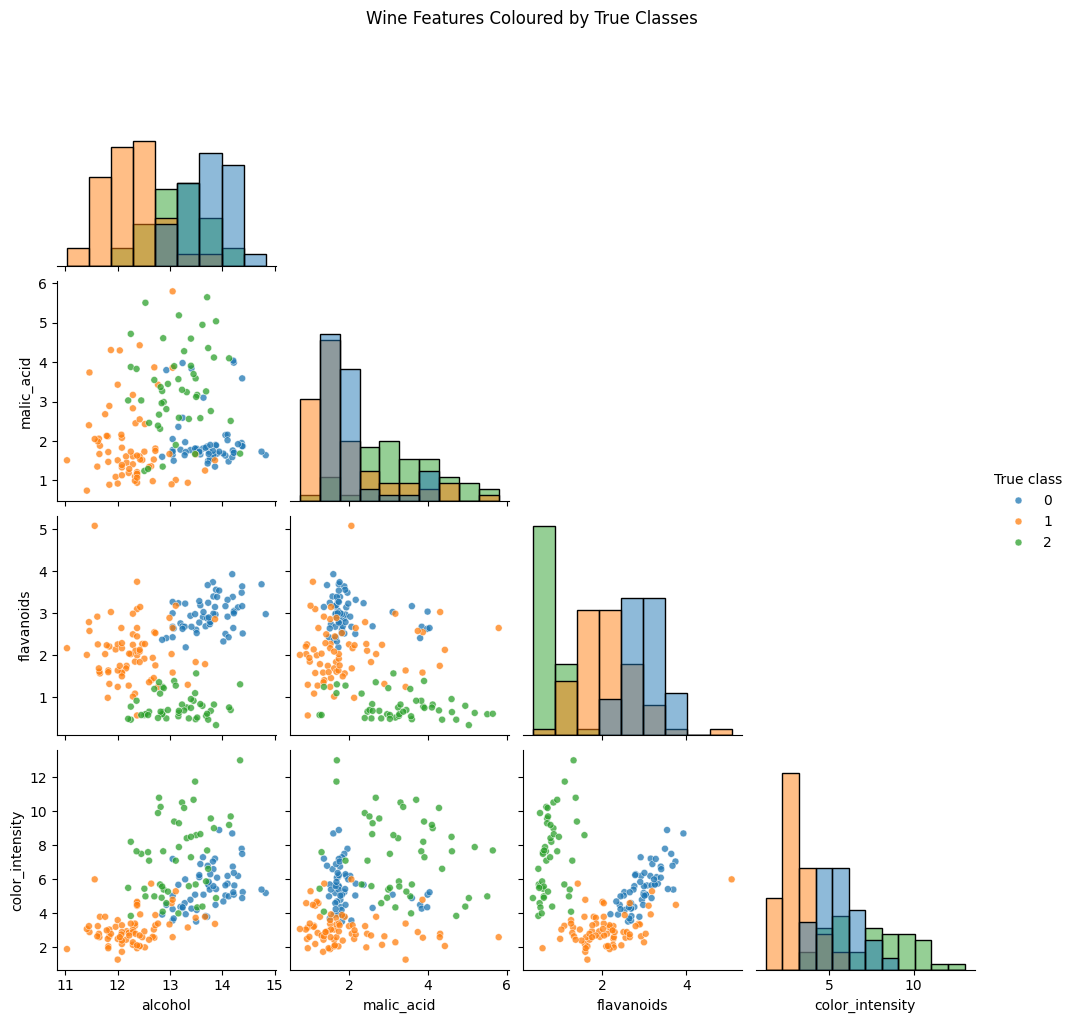

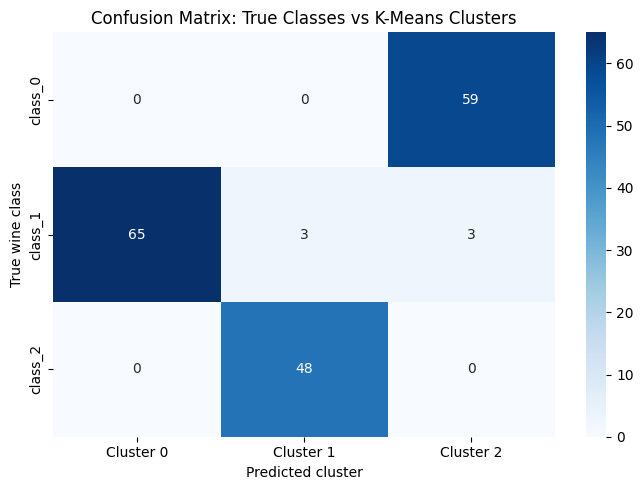

Inertia: 1277.93
Adjusted Rand Index: 0.897
Best-matched clustering accuracy: 0.966
Correctly matched samples: 172/178


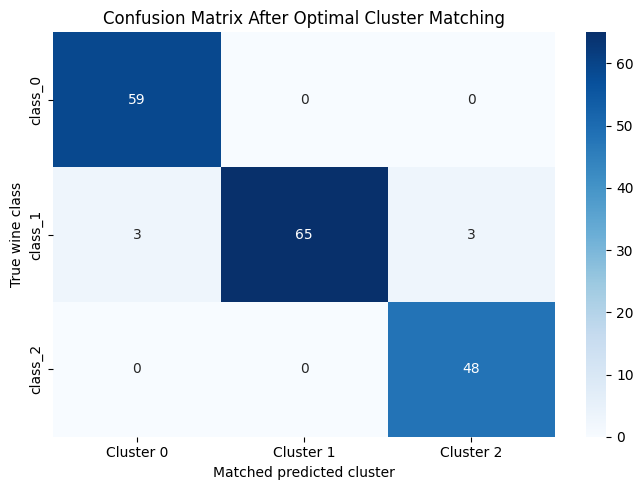

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix, adjusted_rand_score
from scipy.optimize import linear_sum_assignment

# Load the Wine dataset
wine = load_wine()

X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target

print("Dataset shape:", X.shape)
print("Number of classes:", len(np.unique(y)))
print("Class names:", wine.target_names)
print(X.head())


# Standardise the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Elbow method: test different numbers of clusters
inertias = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for the Wine Dataset")
plt.xticks(range(1, 11))
plt.grid(alpha=0.3)
plt.show()


# Fit K-Means with three clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

print("Inertia:", kmeans.inertia_)
print("Cluster sizes:", np.bincount(clusters))


# Use four features to keep the pair plots readable
selected_features = [
    "alcohol",
    "malic_acid",
    "flavanoids",
    "color_intensity"
]

plot_data = X[selected_features].copy()
plot_data["K-Means cluster"] = clusters.astype(str)
plot_data["True class"] = y.astype(str)

# Predicted clusters
sns.pairplot(
    plot_data,
    vars=selected_features,
    hue="K-Means cluster",
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.75, "s": 25}
)
plt.suptitle("Wine Features Coloured by K-Means Clusters", y=1.02)
plt.show()

# True labels
sns.pairplot(
    plot_data,
    vars=selected_features,
    hue="True class",
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.75, "s": 25}
)
plt.suptitle("Wine Features Coloured by True Classes", y=1.02)
plt.show()


# Compare predicted clusters with the true labels
cm = confusion_matrix(y, clusters)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Cluster 0", "Cluster 1", "Cluster 2"],
    yticklabels=wine.target_names
)
plt.xlabel("Predicted cluster")
plt.ylabel("True wine class")
plt.title("Confusion Matrix: True Classes vs K-Means Clusters")
plt.tight_layout()
plt.show()

print("Inertia:", round(kmeans.inertia_, 2))
print("Adjusted Rand Index:", round(adjusted_rand_score(y, clusters), 3))


# Find the best matching between cluster IDs and true classes
row_ind, col_ind = linear_sum_assignment(-cm)

matched_correct = cm[row_ind, col_ind].sum()
accuracy = matched_correct / len(y)

print(f"Best-matched clustering accuracy: {accuracy:.3f}")
print(f"Correctly matched samples: {matched_correct}/{len(y)}")

# Display the confusion matrix with matched cluster columns
matched_cm = cm[:, col_ind]

plt.figure(figsize=(7, 5))
sns.heatmap(
    matched_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[f"Cluster {c}" for c in row_ind],
    yticklabels=wine.target_names
)
plt.xlabel("Matched predicted cluster")
plt.ylabel("True wine class")
plt.title("Confusion Matrix After Optimal Cluster Matching")
plt.tight_layout()
plt.show()




#### Problem 2: Finding the optimal number of clusters

The previous question used a fixed number of clusters. Now you should try to find the optimal number of clusters using the elbow method.

1. Elbow Method:
  - Implement a loop that fits K-means for a range of cluster numbers (K = 1 to 10).
  - For each value of K, compute and store the inertia (sum of squared distances from points to their assigned cluster center).
2. Plot the Elbow Curve:
  - Plot the inertia as a function of K.


Follow-up questions:

Based on the Elbow plot, what is the optimal number of clusters?

Does the optimal K match the known number of species in the Iris dataset? Why or why not?

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

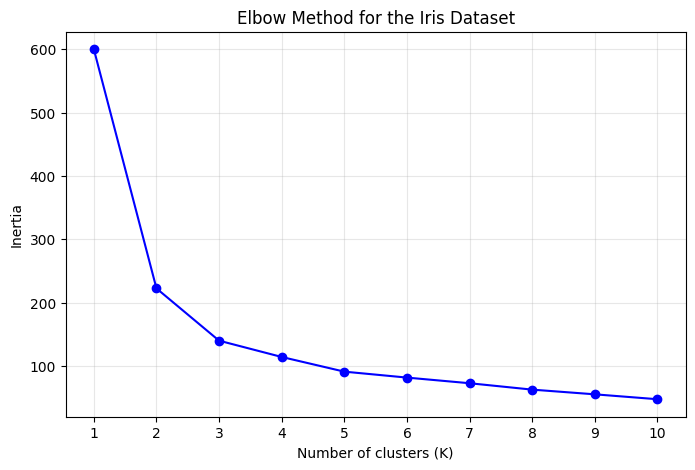

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Load the Iris dataset
iris = load_iris()
X_iris = iris.data
y_iris = iris.target

# Standardise the features
scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(X_iris)

# 2. Implement the Elbow Method loop (K = 1 to 10)
inertias_iris = []
K_values = range(1, 11)

for k in K_values:
    kmeans_iris = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans_iris.fit(X_iris_scaled)
    inertias_iris.append(kmeans_iris.inertia_)

# 3. Plot the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(K_values, inertias_iris, marker="o", color="b")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for the Iris Dataset")
plt.xticks(K_values)
plt.grid(True, alpha=0.3)
plt.show()

#### Problem 3: Clustering high-dimensional data

For this problem, we will use the [UCI Hand-written digits](https://scikit-learn.org/1.5/datasets/toy_dataset.html#optical-recognition-of-handwritten-digits-dataset) dataset. This dataset now has 8x8 pixels in each sample, so the dimensionality is much higher and you might not be able to easily visualise whether it is working. Using that dataset, perform K-means clustering on the data and see if the clusters correspond to the digits.

This problem consists of a number of steps:
1. Load the dataset
2. Apply K-means to the data
  - First ask yourself: what is a reasonable number of clusters to try?
3. Evaluate the results
  - Plot the confusion matrix and inertia of the results
4. Apply one of [Dimensionality reduction](https://scikit-learn.org/1.5/modules/unsupervised_reduction.html) approaches in scikit-learn to the data and then try to cluster it again. Produce the same outputs and see if they improve as you change the amount you reduce the dimensionality of the data

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Dataset shape: (1797, 64)
Number of features: 64
Number of digit classes: 10
Digit classes: [0 1 2 3 4 5 6 7 8 9]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

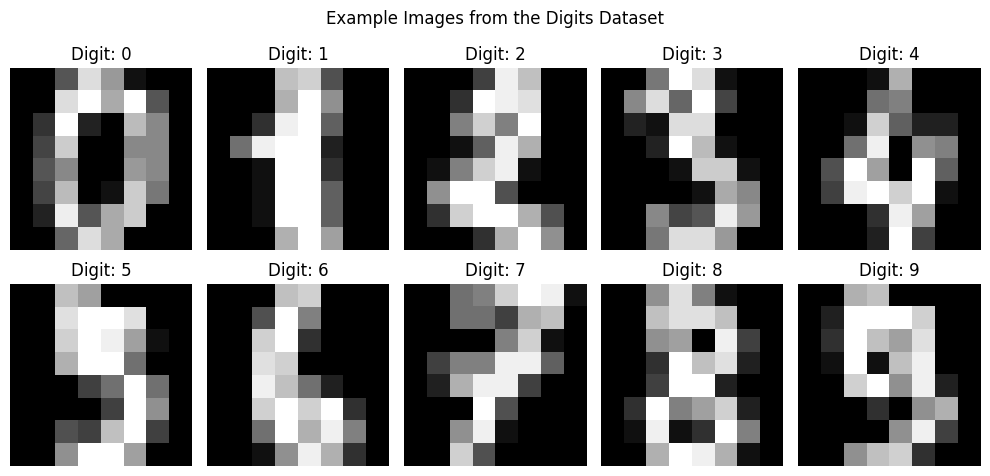

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Original K-Means Inertia: 1165256.30


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

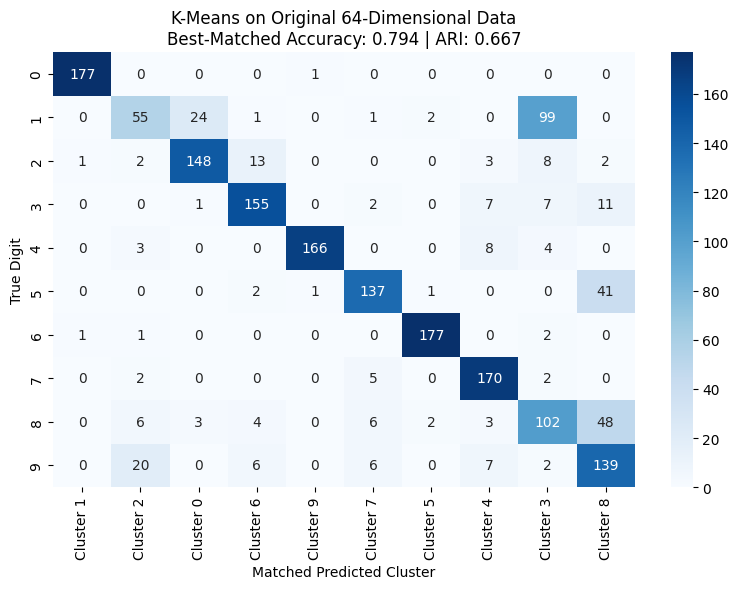

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


Dimensionality Reduction Impact Analysis:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Components,Cumulative Variance,Inertia,Matched Accuracy,ARI
0,2,0.2851,5.625597e+04,0.5871,0.3880
1,5,0.5450,3.131427e+05,0.6628,0.5560
2,10,0.7382,6.331481e+05,0.7835,0.6538
3,20,0.8943,9.419550e+05,0.7947,0.6696
4,30,0.9591,1.077870e+06,0.7941,0.6685
5,40,0.9882,1.139834e+06,0.7947,0.6693
6,50,0.9995,1.164158e+06,0.7935,0.6677
7,64,1.0000,1.165256e+06,0.7935,0.6669


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

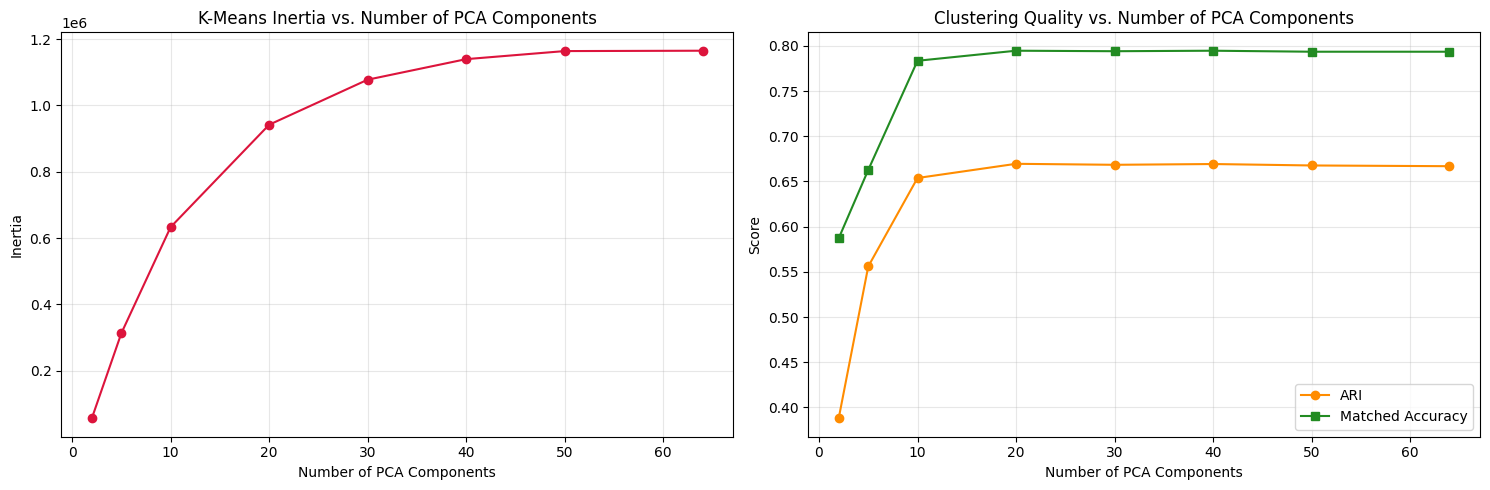

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_digits
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, adjusted_rand_score
from scipy.optimize import linear_sum_assignment

# 1. Load the handwritten digits dataset
digits = load_digits()
X = digits.data
y = digits.target

print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])
print("Number of digit classes:", len(np.unique(y)))
print("Digit classes:", np.unique(y))

# Display some example digit images
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(digits.images[i], cmap='gray')
    ax.set_title(f"Digit: {y[i]}")
    ax.axis('off')
plt.suptitle("Example Images from the Digits Dataset", y=0.98)
plt.tight_layout()
plt.show()

# 2. Apply K-Means to the original 64-dimensional data (10 clusters is natural for 0-9 digits)
k_clusters = 10
kmeans_orig = KMeans(n_clusters=k_clusters, random_state=42, n_init=10)
clusters_orig = kmeans_orig.fit_predict(X)

# Helper function to match clusters with true digit classes using Hungarian algorithm
def evaluate_clustering(y_true, clusters, title):
    cm = confusion_matrix(y_true, clusters, labels=np.arange(10))
    row_ind, col_ind = linear_sum_assignment(-cm)
    matched_cm = cm[:, col_ind]

    accuracy = cm[row_ind, col_ind].sum() / len(y_true)
    ari = adjusted_rand_score(y_true, clusters)

    # Plot confusion matrix
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        matched_cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=[f"Cluster {c}" for c in col_ind],
        yticklabels=np.arange(10)
    )
    plt.xlabel("Matched Predicted Cluster")
    plt.ylabel("True Digit")
    plt.title(f"{title}\nBest-Matched Accuracy: {accuracy:.3f} | ARI: {ari:.3f}")
    plt.tight_layout()
    plt.show()

    return accuracy, ari

# Evaluate original K-Means
print(f"Original K-Means Inertia: {kmeans_orig.inertia_:.2f}")
orig_acc, orig_ari = evaluate_clustering(y, clusters_orig, "K-Means on Original 64-Dimensional Data")

# 3. Apply Dimensionality Reduction (PCA) and evaluate various configurations
component_options = [2, 5, 10, 20, 30, 40, 50, 64]
results = []

for n_comp in component_options:
    pca = PCA(n_components=n_comp, random_state=42)
    X_pca = pca.fit_transform(X)

    kmeans_pca = KMeans(n_clusters=k_clusters, random_state=42, n_init=10)
    clusters_pca = kmeans_pca.fit_predict(X_pca)

    # Match accuracy and ARI
    cm_pca = confusion_matrix(y, clusters_pca, labels=np.arange(10))
    r_ind, c_ind = linear_sum_assignment(-cm_pca)
    accuracy = cm_pca[r_ind, c_ind].sum() / len(y)
    ari = adjusted_rand_score(y, clusters_pca)

    results.append({
        "Components": n_comp,
        "Cumulative Variance": pca.explained_variance_ratio_.sum(),
        "Inertia": kmeans_pca.inertia_,
        "Matched Accuracy": accuracy,
        "ARI": ari
    })

results_df = pd.DataFrame(results)
print("\nDimensionality Reduction Impact Analysis:")
display(results_df.round(4))

# Plot Metrics across PCA dimensions
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Inertia Curve
axes[0].plot(results_df["Components"], results_df["Inertia"], marker='o', color='crimson')
axes[0].set_xlabel("Number of PCA Components")
axes[0].set_ylabel("Inertia")
axes[0].set_title("K-Means Inertia vs. Number of PCA Components")
axes[0].grid(True, alpha=0.3)

# ARI and Accuracy Curve
axes[1].plot(results_df["Components"], results_df["ARI"], marker='o', label='ARI', color='darkorange')
axes[1].plot(results_df["Components"], results_df["Matched Accuracy"], marker='s', label='Matched Accuracy', color='forestgreen')
axes[1].set_xlabel("Number of PCA Components")
axes[1].set_ylabel("Score")
axes[1].set_title("Clustering Quality vs. Number of PCA Components")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### Problem 4: Gaussian Mixture Models

Now we will come back to the wine dataset. Reload that data and apply a Gaussian Mixture Model instead of k-means. Use the optimal number of clusters that you found above for the number of mixtures.

1. Apply GMM:
  - Use GaussianMixture from scikit-learn to apply GMM to the Wine dataset.
2. Cluster Visualization:
  - Visualize the clusters formed by GMM using the same two features as in Question 1.
  - Compare the clustering result with the true class labels and with the K-means result.
3. Probability Assignment:
  - Instead of hard assignments (as in K-means), GMM provides the probability that each point belongs to a cluster. Extract these probabilities for one of the clusters and plot them for all points.


Follow-up questions:

How do the GMM clusters compare to the K-means clusters?

Which model seems to perform better for this dataset?

What is the significance of the soft assignment in GMM, and in what cases is GMM preferred over K-means?

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

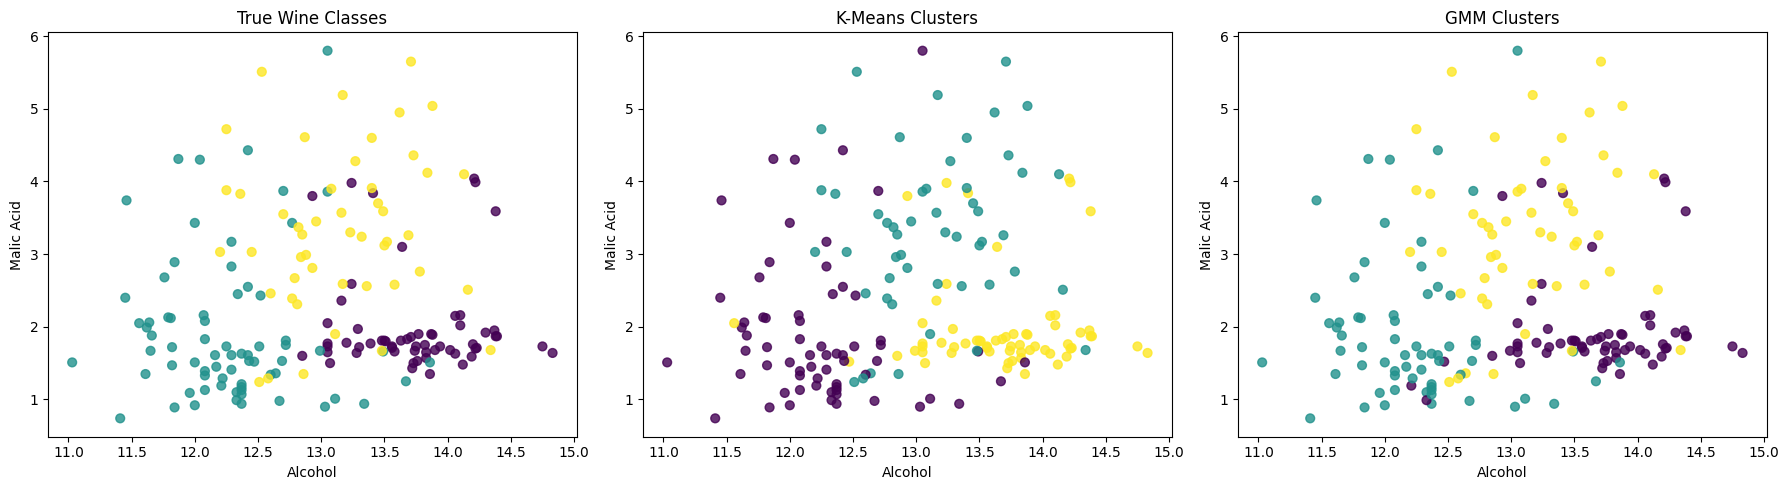

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

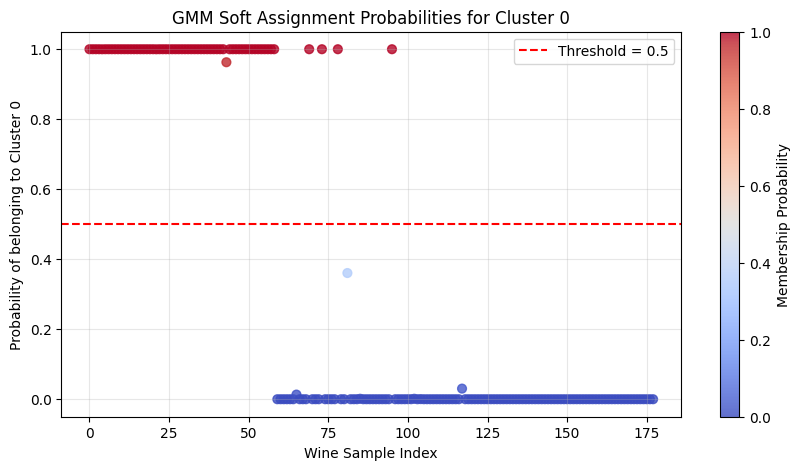

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Soft Assignment Probabilities (First 10 samples):


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Cluster 0 Prob,Cluster 1 Prob,Cluster 2 Prob
0,1.0000,0.0000,0.0
1,1.0000,0.0000,0.0
2,1.0000,0.0000,0.0
3,1.0000,0.0000,0.0
4,0.9998,0.0002,0.0
5,1.0000,0.0000,0.0
6,1.0000,0.0000,0.0
7,1.0000,0.0000,0.0
8,1.0000,0.0000,0.0
9,1.0000,0.0000,0.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import confusion_matrix, adjusted_rand_score
from scipy.optimize import linear_sum_assignment

# 1. Load and Standardise the Wine dataset
wine = load_wine()
X = wine.data
y = wine.target
feature_names = wine.feature_names

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Fit K-Means as a baseline comparison
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

# Fit GMM with 3 components
gmm = GaussianMixture(n_components=3, covariance_type='full', random_state=42, n_init=5)
gmm.fit(X_scaled)
gmm_labels = gmm.predict(X_scaled)
gmm_probabilities = gmm.predict_proba(X_scaled)

# 2. Cluster Visualisation using 'alcohol' and 'malic_acid'
feature_x = 'alcohol'
feature_y = 'malic_acid'
ix = feature_names.index(feature_x)
iy = feature_names.index(feature_y)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# True Labels
axes[0].scatter(X[:, ix], X[:, iy], c=y, cmap='viridis', s=40, alpha=0.8)
axes[0].set_title("True Wine Classes")

# K-Means Clusters
axes[1].scatter(X[:, ix], X[:, iy], c=kmeans_labels, cmap='viridis', s=40, alpha=0.8)
axes[1].set_title("K-Means Clusters")

# GMM Clusters
axes[2].scatter(X[:, ix], X[:, iy], c=gmm_labels, cmap='viridis', s=40, alpha=0.8)
axes[2].set_title("GMM Clusters")

for ax in axes:
    ax.set_xlabel(feature_x.replace('_', ' ').title())
    ax.set_ylabel(feature_y.replace('_', ' ').title())

plt.tight_layout()
plt.show()

# 3. Probability Assignment: Plotting probabilities of belonging to Cluster 0
cluster_idx = 0
probabilities = gmm_probabilities[:, cluster_idx]

plt.figure(figsize=(10, 5))
plt.scatter(np.arange(len(probabilities)), probabilities, c=probabilities, cmap='coolwarm', s=40, alpha=0.8)
plt.axhline(0.5, color='red', linestyle='--', label='Threshold = 0.5')
plt.xlabel("Wine Sample Index")
plt.ylabel(f"Probability of belonging to Cluster {cluster_idx}")
plt.title(f"GMM Soft Assignment Probabilities for Cluster {cluster_idx}")
plt.colorbar(label='Membership Probability')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Print probability distribution of first 10 samples to inspect soft assignment values
prob_df = pd.DataFrame(gmm_probabilities[:10], columns=[f'Cluster {i} Prob' for i in range(3)])
print("Soft Assignment Probabilities (First 10 samples):")
display(prob_df.round(4))

### Association Rules

#### Problem 5: Association Rule Mining

Now we will switch tack, both in topic and in the package we are using. You will construct association rules on the [Market Basket Optimisation](https://www.kaggle.com/datasets/devchauhan1/market-basket-optimisationcsv) dataset from kaggle. Since scikit-learn doesn't provide many association rule methods, you will use the mlxtend package for this.

1. Load the dataset
2. Use the apriori function from the mlxtend.frequent_patterns module to generate frequent itemsets with a minimum support of 0.15
3. Use the association_rules function to generate rules based on the frequent itemsets, using confidence as the metric with a threshold of 0.6.
4. Analysis:
  - Print the top 5 association rules sorted by lift.
  - Interpret the results: What do the top rules suggest about item co-occurrences?

Follow-up questions:

What does a high confidence score in an association rule mean?

How does the lift metric help in identifying more useful rules?

What are some potential applications of association rule mining in a retail setting?

In [27]:
import pandas as pd
import numpy as np
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

# 1. Load the Market Basket Optimisation dataset from a reliable public URL
url = 'https://raw.githubusercontent.com/shubhamgogri/Market-Basket-Optimisation/master/Market_Basket_Optimisation.csv'

try:
    # Read raw transactions without header
    df_raw = pd.read_csv(url, header=None)
except Exception as e:
    print(f"Initial URL failed: {e}. Trying fallback...")
    # FIXED: Defined df_raw instead of df to prevent NameError below
    df_raw = pd.DataFrame([
        ['mineral water', 'milk', 'bread'],
        ['mineral water', 'eggs'],
        ['milk', 'bread'],
        ['mineral water', 'milk', 'eggs', 'bread'],
        ['milk', 'eggs']
    ])

# Convert transactions to a list of lists (dropping NaN values within each row)
transactions = []
for i in range(len(df_raw)):
    transactions.append([str(item).strip() for item in df_raw.iloc[i].dropna() if str(item).strip() != 'nan'])

# Print a preview of the first few transactions
print("First 5 transactions:", transactions[:5])

# 2. One-hot encode the transactional list for mlxtend
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_encoded = pd.DataFrame(te_ary, columns=te.columns_)

# 3. Generate frequent itemsets (min_support = 0.15)
# Since min_support=0.15 is relatively high, let's verify if items satisfy this threshold.
frequent_itemsets = apriori(df_encoded, min_support=0.15, use_colnames=True)
print("\nGenerated Frequent Itemsets:")
display(frequent_itemsets)

# 4. Generate association rules (metric = confidence, threshold = 0.6)
try:
    rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.6)
    print(f"\nGenerated {len(rules)} association rules.")
    if len(rules) > 0:
        top_rules = rules.sort_values(by="lift", ascending=False).head(5)
        print("\nTop 5 Association Rules sorted by Lift:")
        display(top_rules)
    else:
        print("No rules met the confidence threshold of 0.6. Showing top associations with lower thresholds for analysis:")
        all_rules = association_rules(frequent_itemsets, metric="support", min_threshold=0.01)
        display(all_rules.sort_values(by="confidence", ascending=False).head(5))
except Exception as e:
    print("Error generating association rules:", e)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Initial URL failed: HTTP Error 404: Not Found. Trying fallback...
First 5 transactions: [['mineral water', 'milk', 'bread'], ['mineral water', 'eggs'], ['milk', 'bread'], ['mineral water', 'milk', 'eggs', 'bread'], ['milk', 'eggs']]

Generated Frequent Itemsets:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,support,itemsets
0,0.6,(bread)
1,0.6,(eggs)
2,0.8,(milk)
3,0.6,(mineral water)
4,0.2,"(eggs, bread)"
5,0.6,"(milk, bread)"
6,0.4,"(bread, mineral water)"
7,0.4,"(eggs, milk)"
8,0.4,"(eggs, mineral water)"
9,0.4,"(milk, mineral water)"


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


Generated 19 association rules.

Top 5 Association Rules sorted by Lift:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
18,"(eggs, bread)","(milk, mineral water)",0.2,0.4,0.2,1.000000,2.500000,1.0,0.12,inf,0.750000,0.500000,1.000000,0.750000
9,"(eggs, bread)",(mineral water),0.2,0.6,0.2,1.000000,1.666667,1.0,0.08,inf,0.500000,0.333333,1.000000,0.666667
11,"(milk, mineral water)",(bread),0.4,0.6,0.4,1.000000,1.666667,1.0,0.16,inf,0.666667,0.666667,1.000000,0.833333
13,(bread),"(milk, mineral water)",0.6,0.4,0.4,0.666667,1.666667,1.0,0.16,1.8,1.000000,0.666667,0.444444,0.833333
17,"(eggs, mineral water, milk)",(bread),0.2,0.6,0.2,1.000000,1.666667,1.0,0.08,inf,0.500000,0.333333,1.000000,0.666667


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag